In [15]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [16]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'CCCA')

In [17]:
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [18]:
fn = os.path.join(pth_data, 'summary.csv')
df_summary = pd.read_csv(fn, index_col = 0)
labels_dict = df_summary.Signature.dropna().to_dict()
labels_dict

{'GSE162534': 'Mes1', 'GSE229103': 'Mes2', 'rRNAModifications': 'Mes3'}

In [19]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
for src, df_src in feat_dict.items():
    if src != 'union':
        print(src)
        g = df_src.hsapiens.drop_duplicates()
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = src,
                              ctrl_as_ref = False,
                              random_state = 1234)
            adata.obs.loc[msk, src] = adata_group.obs[src]

GSE162534


GSE229103
rRNAModifications


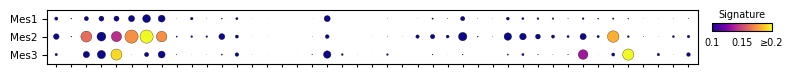

In [42]:
ix = (adata.obs.groupby(
      ['Category', 'Disease'], observed = True)
      .first().reset_index().Disease)

# signatures dotplot
fs, src = 7, list(labels_dict.keys())
dp = sc.pl.dotplot(adata, src, 'Disease',
                   categories_order = ix,
                   expression_cutoff = .1,
                   dot_max = .8,
                   vmin = .1, vmax = .2,
                   cmap = 'plasma',
                   figsize = (9.5, .7),
                   swap_axes = True,
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 90,
         x_padding = .6,
         y_padding = .5)
dp.legend(width = .8)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']
ax_size.set_visible(False)

cax.set_title('Signature', size = fs, pad = 4)
cax.set_xticks([.1, .15, .2], ['0.1', '0.15', '≥0.2'])
cax.tick_params('x', size = 0, labelsize = fs, pad = 4.5)

pos_main = ax_main.get_position()
pos_color = cax.get_position()
cax.set_position([.985 * pos_color.x0,
                  pos_main.y0 + .6 * pos_main.height,
                  pos_color.width,
                  .15 * pos_main.height])

ax_main.set_yticklabels([labels_dict[lbl.get_text()] for
                         lbl in ax_main.get_yticklabels()],
                        fontsize = fs + .5)

ax_main.set_xticklabels([])
ax_main.tick_params('x', size = 2.5)

fn = os.path.join(pth_out, 'signatures.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [7]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))